# Lab 7-01：用官方 SDK 當 client，把 MCP 工具接上本地模型

**目標**：用官方 `mcp` SDK 啟動 `servers/ops_server.py`，列出工具、呼叫工具、讀資源；
再把 MCP 工具轉成 OpenAI 的 tool 格式，交給 `qwen2.5:3b`，做出一個會查日誌的值班小幫手。

**你會學到**
- server 端：函式簽名與型別註記怎麼自動變成工具說明
- client 端：`initialize` → `list_tools` → `call_tool` 的標準流程
- 參數驗證發生在 server 邊界：模型亂填參數會被擋下，並收到看得懂的錯誤
- Tools 和 Resources 差在「誰決定要用」
- 模組 5 的 function calling 迴圈，換成 MCP 工具後一行都不用改

**前置**：先讀 `00_concepts.md`（MCP 原理紀要）；Ollama 已有 `qwen2.5:3b`；模組 5 的 function calling 迴圈（看過即可）。

**對應投影片**：「三角色架構」「三種原語：誰決定用」「Lab7 Server 程式」「客戶端接 MCP」

![MCP 三角色：Host 裡的 LLM 透過 Client A、Client B 分別連到 ops 與 excel 兩支 server](images/mcp_roles.jpg)

*圖：外框是 Host，裡面的 LLM 不直接碰 Server，而是經過 Client；每個 Client 只連一個 Server。朱紅那條就是這本要走的路：notebook 裡的 Client 用 JSON-RPC over stdio 連 `ops_server.py`。*

In [1]:
import json
import os
import sys
import time
from contextlib import asynccontextmanager
from pathlib import Path

import matplotlib.pyplot as plt
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client
from openai import OpenAI

from course_utils.viz import setup_cjk

setup_cjk()
Path("outputs").mkdir(exist_ok=True)
SERVER_LOG = Path("outputs/server_stderr.log")

## Step 1：先讀 server 的程式

`servers/ops_server.py` 是一個虛構公司「星港物流」的維運查詢 server，資料是寫死的假資料。
看它怎麼定義一個工具：一般的 Python 函式，加上 `@mcp.tool()`。

In [2]:
src = Path("servers/ops_server.py").read_text(encoding="utf-8")
start = src.index("mcp = FastMCP")
print(src[start:start + 1500])

mcp = FastMCP("ops", instructions="星港物流的唯讀維運查詢：服務狀態、日誌、值班手冊。")
logging.getLogger("mcp").setLevel(logging.WARNING)  # 關掉 SDK 每個請求一行的訊息
READ_ONLY = ToolAnnotations(readOnlyHint=True, openWorldHint=False)


@mcp.tool(annotations=READ_ONLY)
def get_service_status(service: Service) -> str:
    """查詢一個服務目前的狀態：state、p95 延遲（毫秒）、錯誤率、版本。"""
    log.info("get_service_status(%s)", service)
    return json.dumps({"service": service, **STATUS[service]}, ensure_ascii=False)


@mcp.tool(annotations=READ_ONLY)
def search_logs(
    service: Service,
    level: Level | None = None,
    limit: Annotated[int, Field(ge=1, le=20, description="最多回傳幾筆，上限 20")] = 5,
) -> str:
    """查詢某個服務最近的日誌，可依等級（ERROR、WARN、INFO）篩選，新的在前。"""
    log.info("search_logs(%s, %s, %s)", service, level, limit)
    rows = [r for r in LOGS if r["service"] == service and (level is None or r["level"] == level)]
    rows = sorted(rows, key=lambda r: r["time"], reverse=True)[:limit]
    return json.dumps(rows, ensure_ascii=False) if rows 

重點只有三個：
- **函式名稱**變成工具名稱，**docstring** 變成工具說明（模型靠這段話決定要不要用它）。
- **型別註記**變成參數的 JSON Schema：`Literal["payment", ...]` 變成 `enum`，`Field(ge=1, le=20)` 變成上下限。
- `ToolAnnotations(readOnlyHint=True)` 是給 Host 看的標記：「這個工具只讀不寫」。Lab 7-03 會用到它。

檔案最上面還有一句：**這個檔案裡不能有 `print()`**。原因見 `00_concepts.md` 第 6 節：stdio 的 stdout 就是協定通道，印一行字就會把連線弄壞。

## Step 2：連上 server

官方 client 把 `00_concepts.md` 第 4 節的連線流程包好了：
1. `stdio_client` 開子行程、接上 stdin/stdout
2. `ClientSession` 負責 JSON-RPC 的 `id` 配對
3. `initialize()` 打招呼、交換版本與能力

server 寫到 stderr 的日誌，我們導到一個檔案，等一下再看。

In [3]:
params = StdioServerParameters(command=sys.executable, args=["servers/ops_server.py"])
with SERVER_LOG.open("a", encoding="utf-8") as errlog:
    async with stdio_client(params, errlog=errlog) as (read, write):
        async with ClientSession(read, write) as session:
            info = await session.initialize()

print("server：", info.serverInfo.name, "／協定版本：", info.protocolVersion)
print("說明：", info.instructions)
print("能力：tools =", info.capabilities.tools is not None, "／resources =", info.capabilities.resources is not None)

server： ops ／協定版本： 2025-11-25
說明： 星港物流的唯讀維運查詢：服務狀態、日誌、值班手冊。
能力：tools = True ／resources = True


每次都寫三層 `async with` 太囉嗦，包成一個函式。

In [4]:
@asynccontextmanager
async def connect(script: str):
    params = StdioServerParameters(command=sys.executable, args=[script])
    with SERVER_LOG.open("a", encoding="utf-8") as errlog:
        async with stdio_client(params, errlog=errlog) as (read, write):
            async with ClientSession(read, write) as session:
                await session.initialize()
                yield session

notebook 支援在 cell 裡直接寫 `await` 和 `async with`，所以不用自己呼叫 `asyncio.run`。
每次 `async with` 結束，server 子行程就會被關掉；下一個 cell 再開一個新的，成本只有幾十毫秒。

## Step 3：問它有哪些工具（`tools/list`）

In [5]:
async with connect("servers/ops_server.py") as session:
    listed = await session.list_tools()

for tool in listed.tools:
    print(f"■ {tool.name}  唯讀={tool.annotations.readOnlyHint}")
    print(f"  說明：{tool.description}")
    print(f"  參數：{json.dumps(tool.inputSchema['properties'], ensure_ascii=False)}")

■ get_service_status  唯讀=True
  說明：查詢一個服務目前的狀態：state、p95 延遲（毫秒）、錯誤率、版本。
  參數：{"service": {"enum": ["payment", "order", "inventory"], "title": "Service", "type": "string"}}
■ search_logs  唯讀=True
  說明：查詢某個服務最近的日誌，可依等級（ERROR、WARN、INFO）篩選，新的在前。
  參數：{"service": {"enum": ["payment", "order", "inventory"], "title": "Service", "type": "string"}, "level": {"anyOf": [{"enum": ["ERROR", "WARN", "INFO"], "type": "string"}, {"type": "null"}], "default": null, "title": "Level"}, "limit": {"default": 5, "description": "最多回傳幾筆，上限 20", "maximum": 20, "minimum": 1, "title": "Limit", "type": "integer"}}
■ list_services  唯讀=True
  說明：列出可以查詢的服務名稱。
  參數：{}


對照 Step 1 的原始碼：你沒寫任何 JSON Schema，SDK 從型別註記自己生出來了。
`search_logs` 的 `limit` 帶著 `minimum: 1, maximum: 20`，`service` 是三選一的 `enum`。

## Step 4：呼叫工具（`tools/call`）

In [6]:
async with connect("servers/ops_server.py") as session:
    result = await session.call_tool("get_service_status", {"service": "payment"})
    print("isError：", result.isError)
    print(result.content[0].text)

    result = await session.call_tool("search_logs", {"service": "payment", "level": "ERROR", "limit": 3})
    for row in json.loads(result.content[0].text):
        print(row)

isError： False
{"service": "payment", "state": "degraded", "p95_ms": 2310, "error_rate": 0.084, "version": "v3.2.1"}
{'time': '10:05:22', 'service': 'payment', 'level': 'ERROR', 'msg': '連線池耗盡：等待連線逾時 2000ms'}
{'time': '10:03:41', 'service': 'payment', 'level': 'ERROR', 'msg': '呼叫銀行閘道逾時，訂單 A-1182 付款失敗'}
{'time': '10:03:05', 'service': 'payment', 'level': 'ERROR', 'msg': '連線池耗盡：等待連線逾時 2000ms'}


回傳的是一個 `content` 清單，每一塊有 `type`（這裡都是 `text`）。工具也可以回圖片、音訊或資源連結。

## Step 5：先看它壞掉——亂填參數

模型很常把參數填錯：服務名稱打錯、數量超過上限。這些錯在哪裡被擋下？

In [7]:
async with connect("servers/ops_server.py") as session:
    bad = await session.call_tool("search_logs", {"service": "pay", "limit": 99})

print("isError：", bad.isError)
print(bad.content[0].text)

isError： True
Error executing tool search_logs: 2 validation errors for search_logsArguments
service
  Input should be 'payment', 'order' or 'inventory' [type=literal_error, input_value='pay', input_type=str]
    For further information visit https://errors.pydantic.dev/2.12/v/literal_error
limit
  Input should be less than or equal to 20 [type=less_than_equal, input_value=99, input_type=int]
    For further information visit https://errors.pydantic.dev/2.12/v/less_than_equal


server 沒有當掉，也沒有拋例外給 client，而是回一個 `isError=True` 的結果，裡面寫清楚哪個參數錯、該填什麼。
這很重要：這段錯誤訊息會被原封不動交給模型，**模型讀得懂，就有機會自己修正再呼叫一次**。
驗證放在 server 邊界，不管對面是哪個 Host、哪個模型，都擋得住。

## Step 6：Resources——由應用程式決定要不要讀

工具是**模型**決定何時呼叫；資源（Resources）是**應用程式**決定何時讀，通常是在對話開始前塞進 context。
這個 server 提供一份值班手冊：`ops://runbook`。

In [8]:
async with connect("servers/ops_server.py") as session:
    resources = await session.list_resources()
    for r in resources.resources:
        print(f"{r.uri}  ({r.mimeType})  {r.description}")
    runbook = (await session.read_resource("ops://runbook")).contents[0].text

print()
print(runbook)

ops://runbook  (text/markdown)  值班手冊節錄

# 星港物流值班手冊（節錄）
- payment 的 p95 超過 1000ms 或錯誤率超過 5%：視為降級，先查 ERROR 日誌。
- 「連線池耗盡」通常跟最近一次部署有關：比對部署時間。
- 任何重啟、回滾都要先經過值班主管核准，不能由 agent 直接執行。



MCP 還有第三種原語 **Prompts**（使用者主動挑選的提示詞模板，像斜線指令），這個 server 沒有提供，概念上跟 Resources 類似。

## Step 7：server 的日誌跑去哪了？

我們在 Step 2 把 server 的 stderr 導到 `outputs/server_stderr.log`。協定走 stdout，日誌走 stderr，兩條管線互不干擾。

In [9]:
print(SERVER_LOG.read_text(encoding="utf-8").strip().splitlines()[-5:])

['[ops-server] get_service_status(payment)', '[ops-server] search_logs(payment, ERROR, 3)']


## Step 8：MCP 工具 → OpenAI tool 格式

本地 Ollama 走 OpenAI 相容 API。`00_concepts.md` 第 1 節看過，各家格式只差外面那層包裝；MCP 的 `inputSchema` 本來就是 JSON Schema，直接放進 `parameters` 就好。

In [10]:
def to_openai_tool(tool) -> dict:
    return {"type": "function",
            "function": {"name": tool.name, "description": tool.description or "", "parameters": tool.inputSchema}}


spec = to_openai_tool(listed.tools[1])
print(json.dumps(spec, ensure_ascii=False)[:400], "…")

{"type": "function", "function": {"name": "search_logs", "description": "查詢某個服務最近的日誌，可依等級（ERROR、WARN、INFO）篩選，新的在前。", "parameters": {"properties": {"service": {"enum": ["payment", "order", "inventory"], "title": "Service", "type": "string"}, "level": {"anyOf": [{"enum": ["ERROR", "WARN", "INFO"], "type": "string"}, {"type": "null"}], "default": null, "title": "Level"}, "limit": {"default": 5, "desc …


這就是 N+M 裡的「+N」：每種模型 API 只要寫一次這個轉換函式，就能用任何 MCP server 的工具。

## Step 9：接上模型——就是模組 5 的那個迴圈

迴圈跟模組 5 一樣：模型回 `tool_calls` 就去執行、把結果塞回 messages，沒有 `tool_calls` 就是最終答案。
唯一的差別是「執行」那一行從呼叫本地 Python 函式，改成 `session.call_tool(...)`。
另外設了 `max_turns` 上限，避免模型陷入無限呼叫；每一步都記下耗時，等一下畫圖。

In [11]:
llm = OpenAI(base_url=os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1"), api_key="ollama")
MODEL = os.getenv("LOCAL_MODEL", "qwen2.5:3b")


async def run_agent(session, system: str, question: str, max_turns: int = 6) -> tuple[str, list]:
    tools = [to_openai_tool(t) for t in (await session.list_tools()).tools]
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    trace = []  # (種類, 名稱, 秒數)
    for _ in range(max_turns):
        t0 = time.perf_counter()
        msg = llm.chat.completions.create(model=MODEL, messages=messages, tools=tools, temperature=0).choices[0].message
        trace.append(("模型", "思考", time.perf_counter() - t0))
        messages.append(msg.model_dump(exclude_none=True))
        if not msg.tool_calls:
            return msg.content, trace
        for call in msg.tool_calls:
            args = json.loads(call.function.arguments or "{}")
            t0 = time.perf_counter()
            result = await session.call_tool(call.function.name, args)
            trace.append(("工具", call.function.name, time.perf_counter() - t0))
            text = "\n".join(c.text for c in result.content if c.type == "text")
            print(f"  [呼叫] {call.function.name}({args}) → {'錯誤：' if result.isError else ''}{text[:120]}")
            messages.append({"role": "tool", "tool_call_id": call.id, "content": text})
    return "（超過 max_turns，停止）", trace

## Step 10：問它一個值班問題

系統提示詞裡放進 Step 6 讀到的值班手冊——這就是「資源由應用程式決定要不要用」的實際樣子。

In [12]:
SYSTEM = "你是星港物流的值班助理。先用工具查資料再回答，用繁體中文，簡短。\n\n" + runbook

async with connect("servers/ops_server.py") as session:
    answer, trace = await run_agent(session, SYSTEM, "payment 服務現在狀況如何？最近有哪些 ERROR？可能的原因是什麼？")

print("\n答：", answer)

  [呼叫] get_service_status({'service': 'payment'}) → {"service": "payment", "state": "degraded", "p95_ms": 2310, "error_rate": 0.084, "version": "v3.2.1"}
  [呼叫] search_logs({'service': 'payment', 'level': 'ERROR'}) → [{"time": "10:05:22", "service": "payment", "level": "ERROR", "msg": "連線池耗盡：等待連線逾時 2000ms"}, {"time": "10:03:41", "servi

答： payment 服務目前狀態為降級，p95 延遲為 2310 毫秒，錯誤率為 0.084 或 8.4%。

最近的錯誤日誌顯示，有三次連線池耗盡的錯誤，每次等待連線逾時 2000 毫秒。這可能是最近一次部署的結果，因為連線池耗盡通常與最近的部署有關。

可能的原因是連接問題或部署問題。部署時可能引入了影響連接的變更，導致連接池耗盡。


模型呼叫了 `get_service_status` 和 `search_logs`，再搭配手冊裡「連線池耗盡通常跟最近一次部署有關」做出判斷。
它答得好不好，取決於工具回傳的資料，而不是模型自己記得什麼。

## Step 11：時間都花在哪？

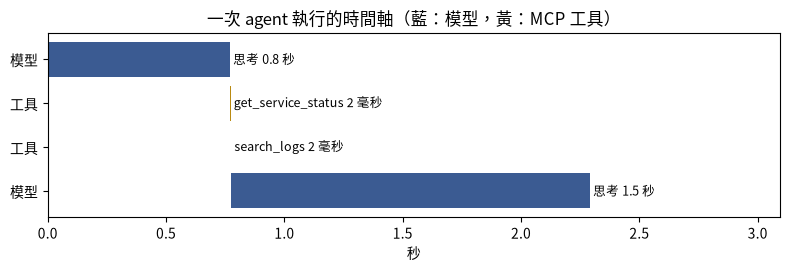

總共 2.3 秒，其中 MCP 工具只佔 5 毫秒


In [13]:
fig, ax = plt.subplots(figsize=(8, 2.8))
t = 0.0
for i, (kind, name, sec) in enumerate(trace):
    color = "#3b5b92" if kind == "模型" else "#b98a12"
    ax.barh(i, sec, left=t, color=color)
    label = f"{sec:.1f} 秒" if kind == "模型" else f"{sec * 1000:.0f} 毫秒"
    ax.text(t + sec, i, f" {name} {label}", va="center", fontsize=9)
    t += sec
ax.set_yticks(range(len(trace)), [k for k, _, _ in trace])
ax.invert_yaxis()
ax.set_xlabel("秒")
ax.set_title("一次 agent 執行的時間軸（藍：模型，黃：MCP 工具）")
ax.set_xlim(0, t * 1.35)
plt.tight_layout()
plt.show()

tool_sec = sum(s for k, _, s in trace if k == "工具")
print(f"總共 {t:.1f} 秒，其中 MCP 工具只佔 {tool_sec * 1000:.0f} 毫秒")

幾乎所有時間都花在模型推論，MCP 的協定開銷可以忽略。要讓 agent 變快，該省的是模型呼叫次數，不是工具。

## Step 12：同一個迴圈，換一個 server

`run_agent` 裡沒有任何一行跟「維運」有關。換一個 server，它就變成另一種 agent。
下一本要用的 `servers/excel_server.py`，現在就能接：

In [14]:
async with connect("servers/excel_server.py") as session:
    for tool in (await session.list_tools()).tools:
        print(f"■ {tool.name}：{tool.description.splitlines()[0]}")

■ list_sheets：列出 Excel 檔裡的所有工作表與各自的列數。
■ describe：看一張工作表的結構：欄位名稱、型別、前 3 列範例。分析前先呼叫這個。
■ query：彙總查詢（唯讀）：先依 where 篩選，再依 group_by 分組，對 value_column 做 agg，由大到小排序。
■ make_chart：畫圖並存成 PNG（不改原始檔）。line 適合時間趨勢（x 用 月份），bar 適合類別比較。回傳圖檔路徑、最大值與每個點的數字。


## 試試看

1. 問一個需要比較多個服務的問題，例如「三個服務裡哪個不健康？」，看模型會不會先呼叫 `list_services`。
2. 把 `SYSTEM` 裡的值班手冊拿掉，再問 Step 10 的問題，比較「可能的原因」答得有沒有根據。
3. 在 `ops_server.py` 新增一個唯讀工具 `get_deploy_history(service)`（回傳假的部署紀錄），不改任何 client 程式，重跑 Step 3 確認它出現了。

## 小結

- server 端寫普通函式加型別註記，SDK 自動產生工具說明並在邊界驗證參數；錯誤會變成模型讀得懂的訊息。
- client 端流程固定：`initialize` → `list_tools` → `call_tool`；Tools 由模型決定何時用，Resources 由應用程式決定。
- 模組 5 的迴圈換成 MCP 工具一行不改；下一本用同一套做 Lab 7：一個會查 Excel、會畫圖的分析 agent。